In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
reviews = pd.read_csv(
    "../data/processed/reviews_cleaned.csv"
)

accommodation = pd.read_csv(
    "../data/processed/accommodation_cleaned.csv"
)

activities = pd.read_csv(
    "../data/processed/activities_cleaned.csv"
)

water_sports = pd.read_csv(
    "../data/processed/water_sports_cleaned.csv"
)

In [3]:
print("Reviews:", reviews.shape)
print("Accommodation:", accommodation.shape)
print("Activities:", activities.shape)
print("Water Sports:", water_sports.shape)

Reviews: (16156, 16)
Accommodation: (2130, 10)
Activities: (1523, 7)
Water Sports: (25, 5)


In [5]:
reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16156 entries, 0 to 16155
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Location_Name       16156 non-null  object
 1   Located_City        16156 non-null  object
 2   Location            16156 non-null  object
 3   Location_Type       16156 non-null  object
 4   User_ID             16156 non-null  object
 5   User_Location       16156 non-null  object
 6   User_Locale         16156 non-null  object
 7   User_Contributions  16156 non-null  int64 
 8   Travel_Date         16156 non-null  object
 9   Published_Date      16156 non-null  object
 10  Rating              16156 non-null  int64 
 11  Helpful_Votes       16156 non-null  int64 
 12  Title               16153 non-null  object
 13  Text                16156 non-null  object
 14  Travel_Year         16156 non-null  int64 
 15  Travel_Month        16156 non-null  int64 
dtypes: int64(5), object(11

In [6]:
accommodation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2130 entries, 0 to 2129
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Type          2130 non-null   object 
 1   Name          2130 non-null   object 
 2   Address       2130 non-null   object 
 3   Rooms         2130 non-null   int64  
 4   Grade         2130 non-null   object 
 5   District      2130 non-null   object 
 6   AGA Division  2130 non-null   object 
 7   PS/MC/UC      2130 non-null   object 
 8   Logitiute     1368 non-null   float64
 9   Latitude      1370 non-null   float64
dtypes: float64(2), int64(1), object(7)
memory usage: 166.5+ KB


In [7]:
activities.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1523 entries, 0 to 1522
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Type          1523 non-null   object
 1   Name          1523 non-null   object
 2   Address       1523 non-null   object
 3   Grade         1523 non-null   object
 4   District      1523 non-null   object
 5   AGA Division  1523 non-null   object
 6   PS/MC/UC      1523 non-null   object
dtypes: object(7)
memory usage: 83.4+ KB


In [8]:
water_sports.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Name          25 non-null     object
 1   Address       25 non-null     object
 2   District      25 non-null     object
 3   AGA Division  25 non-null     object
 4   PS/MC/UC      25 non-null     object
dtypes: object(5)
memory usage: 1.1+ KB


Analysis 1: Rating Distribution

In [9]:
rating_counts = reviews["Rating"].value_counts().sort_index()

print(rating_counts)

Rating
1     487
2     658
3    2166
4    5196
5    7649
Name: count, dtype: int64


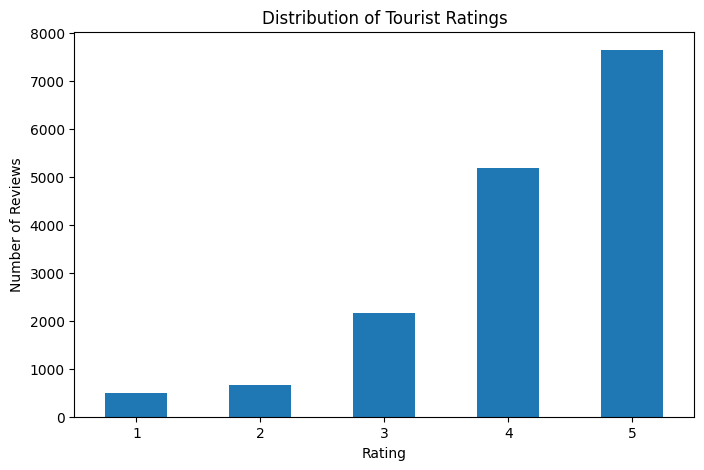

In [10]:
plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar")

plt.title("Distribution of Tourist Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

Analysis 2: Average Rating

In [11]:
average_rating = reviews["Rating"].mean()

print(f"Average Tourist Rating: {average_rating:.2f}")

Average Tourist Rating: 4.17


Analysis 3: Top 10 Most Reviewed Destinations

In [12]:
top_destinations = (
    reviews["Location_Name"]
    .value_counts()
    .head(10)
)

print(top_destinations)

Location_Name
Pinnawala Elephant Orphanage    369
Royal Botanical Gardens         337
Polonnaruwa                     333
Wilpattu National Park          326
Dambulla Cave Temple            321
Sigiriya Museum                 314
Bluefield Tea Gardens           314
Ceylon Tea Museum               305
Handunugoda Tea Estate          304
Glenloch Tea Factory            302
Name: count, dtype: int64


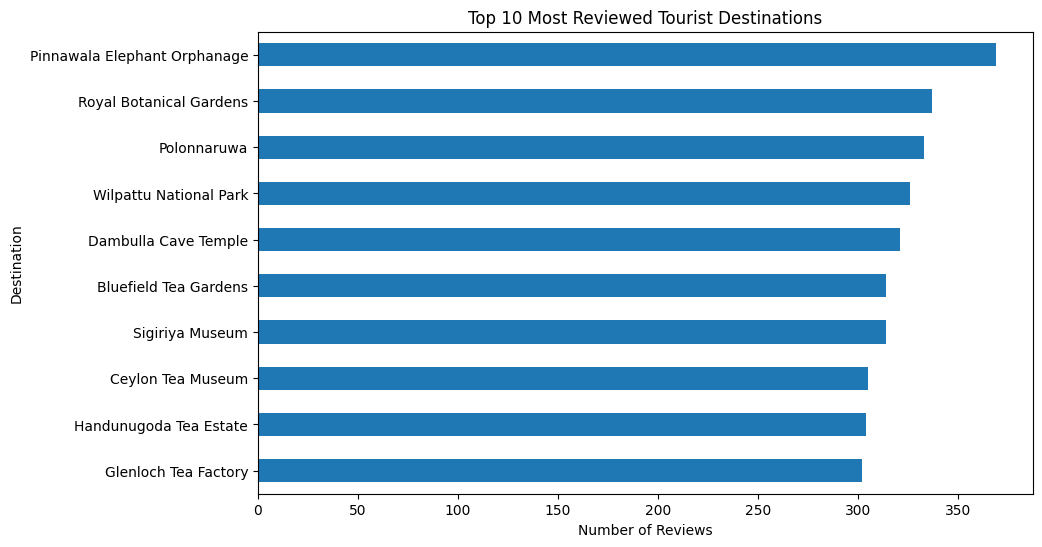

In [13]:
plt.figure(figsize=(10, 6))

top_destinations.sort_values().plot(kind="barh")

plt.title("Top 10 Most Reviewed Tourist Destinations")
plt.xlabel("Number of Reviews")
plt.ylabel("Destination")

plt.show()

Analysis 4: Location Type Distribution

In [14]:
location_type_counts = reviews["Location_Type"].value_counts()

print(location_type_counts)

Location_Type
Religious Sites            3017
Beaches                    2110
Farms                      1884
Nature & Wildlife Areas    1557
Museums                    1525
Historic Sites             1519
Gardens                    1354
National Parks             1205
Waterfalls                  933
Bodies of Water             839
Zoological Gardens          213
Name: count, dtype: int64


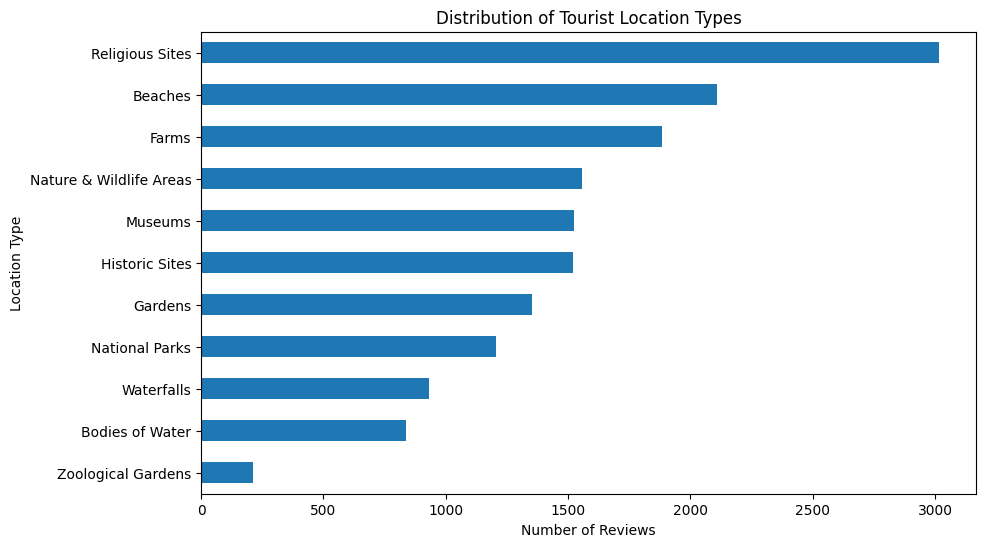

In [15]:
plt.figure(figsize=(10, 6))

location_type_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Tourist Location Types")
plt.xlabel("Number of Reviews")
plt.ylabel("Location Type")

plt.show()

Monthly Travel Pattern

In [16]:
monthly_reviews = (
    reviews["Travel_Month"]
    .value_counts()
    .sort_index()
)

print(monthly_reviews)

Travel_Month
1     2236
2     2168
3     1762
4     1266
5      619
6      619
7     1086
8     1394
9     1122
10    1045
11    1020
12    1819
Name: count, dtype: int64


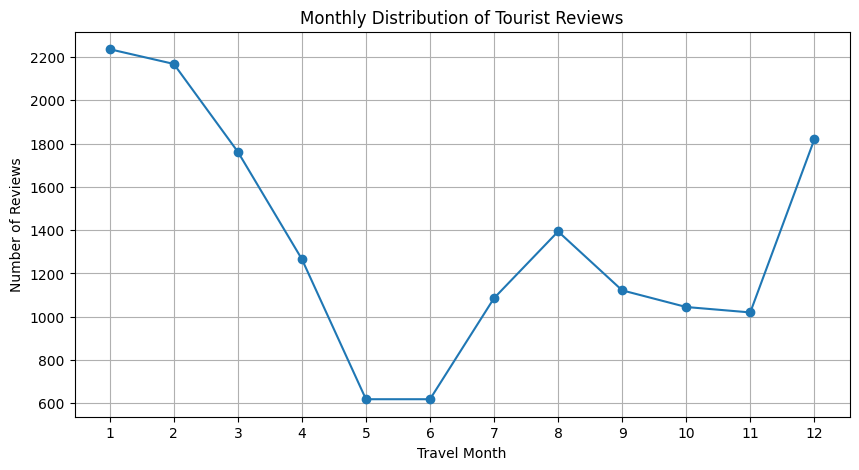

In [17]:
plt.figure(figsize=(10, 5))

monthly_reviews.plot(kind="line", marker="o")

plt.title("Monthly Distribution of Tourist Reviews")
plt.xlabel("Travel Month")
plt.ylabel("Number of Reviews")
plt.xticks(range(1, 13))

plt.grid(True)
plt.show()

In [18]:
yearly_reviews = (
    reviews["Travel_Year"]
    .value_counts()
    .sort_index()
)

print(yearly_reviews)

Travel_Year
2010       2
2011      53
2012     204
2013     343
2014     494
2015    1094
2016    2029
2017    2435
2018    3872
2019    3893
2020    1136
2021     122
2022     342
2023     137
Name: count, dtype: int64


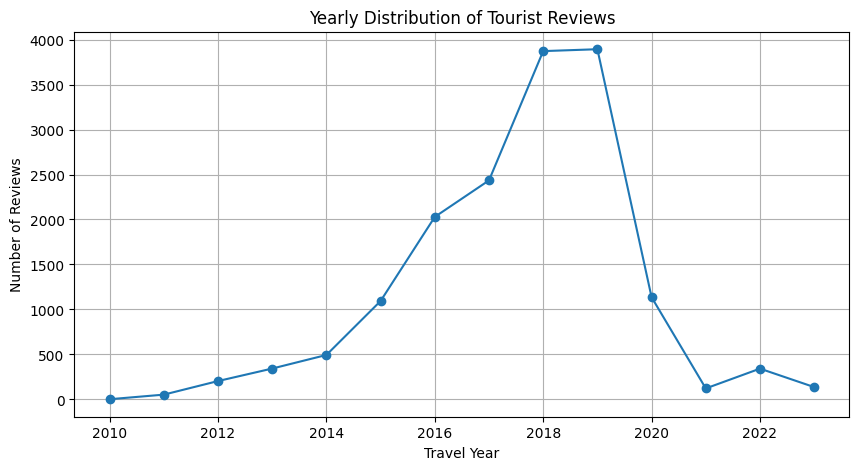

In [19]:
plt.figure(figsize=(10, 5))

yearly_reviews.plot(kind="line", marker="o")

plt.title("Yearly Distribution of Tourist Reviews")
plt.xlabel("Travel Year")
plt.ylabel("Number of Reviews")

plt.grid(True)
plt.show()

Destination × Travel Month Analysis

In [20]:
destination_month = pd.crosstab(
    reviews["Location_Name"],
    reviews["Travel_Month"]
)

destination_month.head()

Travel_Month,1,2,3,4,5,6,7,8,9,10,11,12
Location_Name,,,,,,,,,,,,
Abhayagiri Dagaba,16,17,16,4,8,1,2,7,4,7,6,8
Ambewela Farms,21,6,9,9,9,8,10,16,15,14,7,12
Ariyapala Mask Museum,9,12,10,6,1,2,4,7,6,5,6,9
Arugam Bay,10,11,4,16,12,22,42,35,14,14,4,3
Baker's Falls,7,8,11,11,4,4,4,5,4,2,7,7


In [21]:
top_10_names = reviews["Location_Name"].value_counts().head(10).index

destination_month_top10 = destination_month.loc[top_10_names]

destination_month_top10

Travel_Month,1,2,3,4,5,6,7,8,9,10,11,12
Location_Name,,,,,,,,,,,,
Pinnawala Elephant Orphanage,32,49,27,21,18,29,24,29,27,29,36,48
Royal Botanical Gardens,65,55,53,23,6,2,10,11,24,23,30,35
Polonnaruwa,41,46,52,27,12,9,37,19,22,21,19,28
Wilpattu National Park,37,57,37,25,12,12,28,37,21,22,15,23
Dambulla Cave Temple,45,54,38,22,8,5,5,25,33,22,17,47
Sigiriya Museum,38,30,30,17,15,19,26,36,22,22,26,33
Bluefield Tea Gardens,46,44,35,36,22,6,12,23,22,19,12,37
Ceylon Tea Museum,37,38,29,18,11,17,24,25,31,21,16,38
Handunugoda Tea Estate,48,32,32,39,8,7,18,28,23,14,15,40


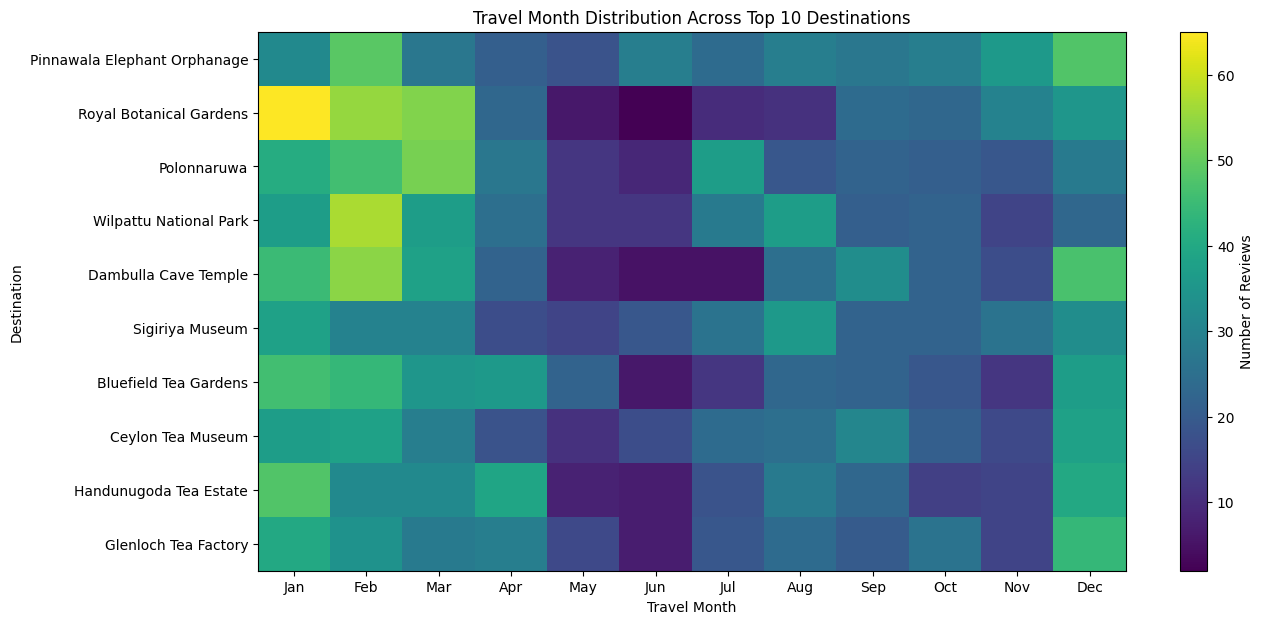

In [22]:
plt.figure(figsize=(14, 7))

plt.imshow(
    destination_month_top10,
    aspect="auto"
)

plt.colorbar(label="Number of Reviews")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.yticks(
    range(len(destination_month_top10)),
    destination_month_top10.index
)

plt.xlabel("Travel Month")
plt.ylabel("Destination")
plt.title("Travel Month Distribution Across Top 10 Destinations")

plt.show()

1. Accommodation Type Distribution

In [23]:
accommodation_type_counts = (
    accommodation["Type"]
    .value_counts()
)

print(accommodation_type_counts)

Type
Guest Houses                    894
Home Stay Units                 378
Bangalows                       348
Tourist Hotels                  229
Classified Hotels( 1-5 Star)    141
Rented Apartments                64
Boutique Villas                  36
Boutique Hotels                  28
Rented Homes                      6
Heritage Bungalows                4
Heritage Homes                    2
Name: count, dtype: int64


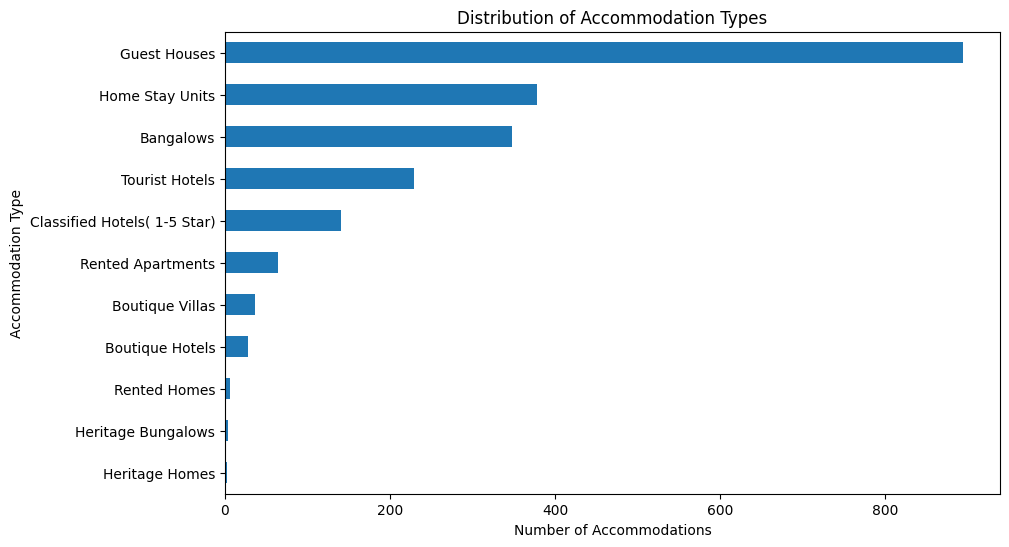

In [24]:
plt.figure(figsize=(10, 6))

accommodation_type_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Accommodation Types")
plt.xlabel("Number of Accommodations")
plt.ylabel("Accommodation Type")

plt.show()

2. Accommodation by District

In [25]:
district_counts = (
    accommodation["District"]
    .value_counts()
    .head(15)
)

print(district_counts)

District
Colombo         297
Galle           284
Kandy           266
Gampaha         207
Kalutara        132
Badulla         116
Nuwara Eliya     93
Matara           88
Matale           86
Hambantota       76
Ampara           62
Anuradhapura     58
Puttalam         54
Kurunegala       48
Batticaloa       44
Name: count, dtype: int64


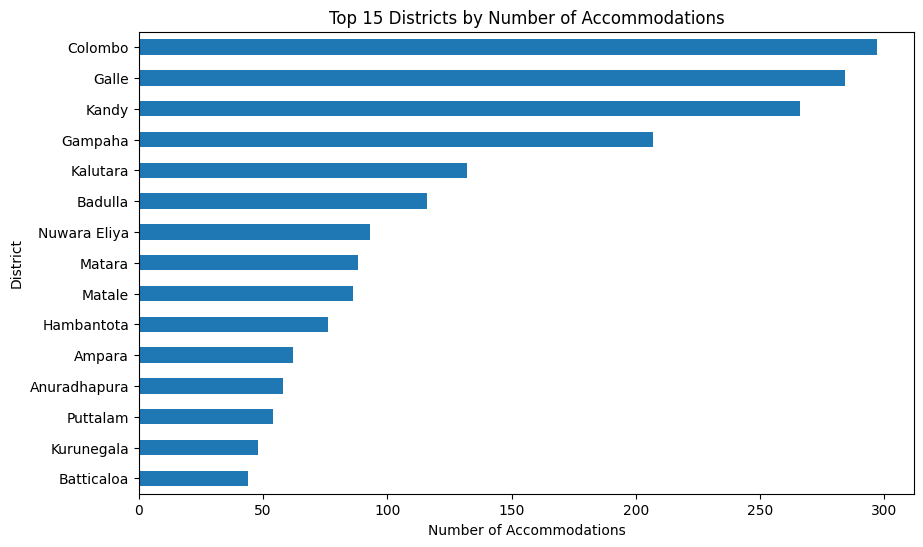

In [26]:
plt.figure(figsize=(10, 6))

district_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Districts by Number of Accommodations")
plt.xlabel("Number of Accommodations")
plt.ylabel("District")

plt.show()

3. Number of Rooms

In [27]:
print(accommodation["Rooms"].describe())

count    2130.000000
mean       16.961972
std        36.657709
min         1.000000
25%         4.000000
50%         6.000000
75%        14.000000
max       541.000000
Name: Rooms, dtype: float64


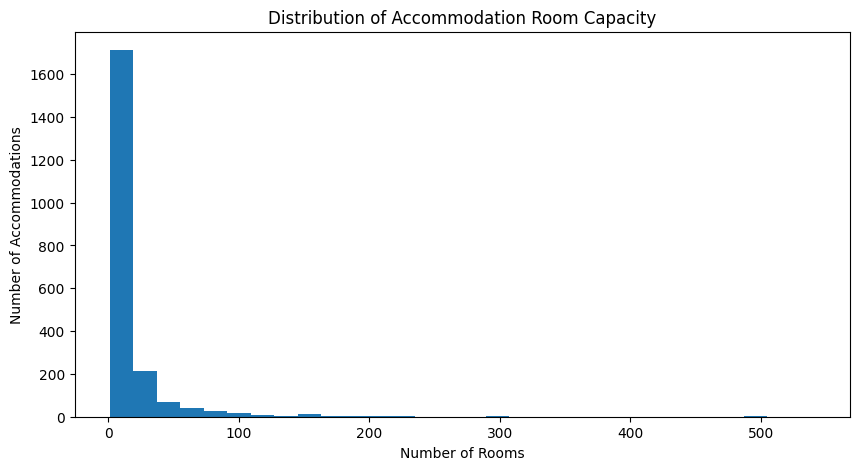

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(accommodation["Rooms"], bins=30)

plt.title("Distribution of Accommodation Room Capacity")
plt.xlabel("Number of Rooms")
plt.ylabel("Number of Accommodations")

plt.show()

In [29]:
grade_counts = accommodation["Grade"].value_counts()

print(grade_counts)

Grade
A           461
B           399
UNKNOWN     293
DELUXE      273
STANDARD    269
SUPERIOR    260
ONE          40
TWO          37
C            34
THREE        25
FIVE         20
FOUR         19
Name: count, dtype: int64


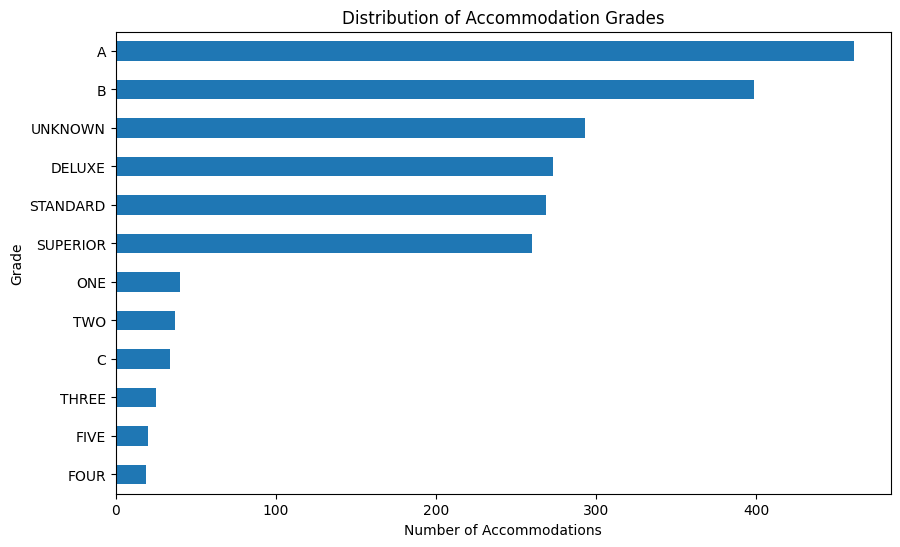

In [30]:
plt.figure(figsize=(10, 6))

grade_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Accommodation Grades")
plt.xlabel("Number of Accommodations")
plt.ylabel("Grade")

plt.show()

In [31]:
type_district = pd.crosstab(
    accommodation["District"],
    accommodation["Type"]
)

type_district.head(10)

Type,Bangalows,Boutique Hotels,Boutique Villas,Classified Hotels( 1-5 Star),Guest Houses,Heritage Bungalows,Heritage Homes,Home Stay Units,Rented Apartments,Rented Homes,Tourist Hotels
District,,,,,,,,,,,
Ampara,1,0,0,0,30,0,0,27,0,0,4
Anuradhapura,9,1,0,8,32,0,0,5,0,0,3
Badulla,19,0,0,0,33,0,0,55,0,0,9
Batticaloa,10,1,0,1,16,0,0,5,0,0,11
Colombo,44,2,1,31,109,0,0,57,38,2,13
Galle,58,9,14,18,110,0,1,29,5,1,39
Gampaha,24,1,0,10,108,0,1,31,3,1,28
Hambantota,11,4,1,7,32,0,0,6,0,0,15
Jaffna,2,0,0,0,23,0,0,0,0,0,4


Activity/Service Type Distribution

In [32]:
activity_type_counts = activities["Type"].value_counts()

print(activity_type_counts)

Type
Travel Agents             852
Restaurants               476
Tourist Shops              74
Spa & Wellness Centers     60
Spice Gardens              36
Water Sports Centers       25
Name: count, dtype: int64


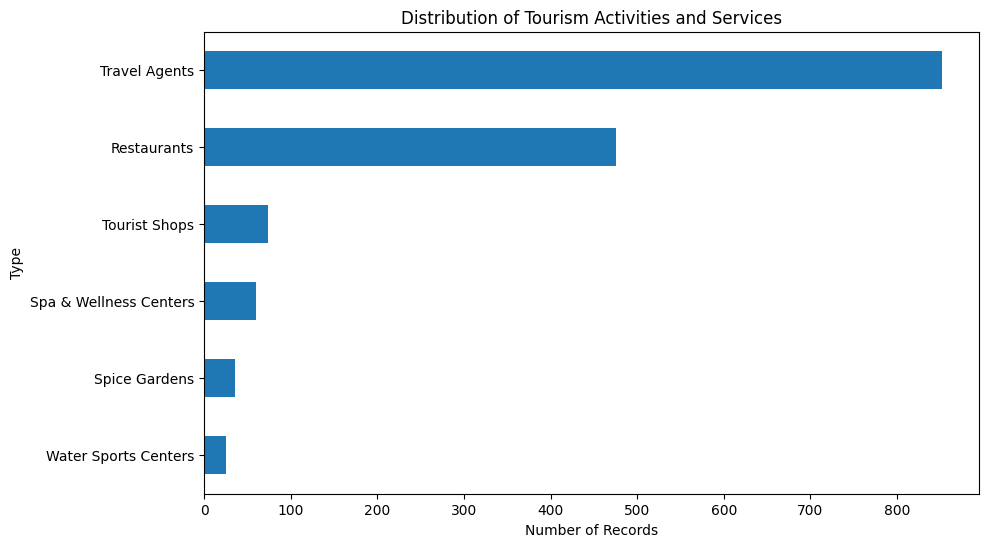

In [33]:
plt.figure(figsize=(10, 6))

activity_type_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Tourism Activities and Services")
plt.xlabel("Number of Records")
plt.ylabel("Type")

plt.show()

In [34]:
activity_district_counts = (
    activities["District"]
    .value_counts()
    .head(15)
)

print(activity_district_counts)

District
Colombo        939
Gampaha        175
Kandy           70
Galle           64
Matale          45
Kalutara        43
Kegalle         35
Puttalam        29
Kurunegala      25
Ampara          15
Matara          13
Jaffna          11
Batticaloa      11
Ratnapura        8
Trincomalee      7
Name: count, dtype: int64


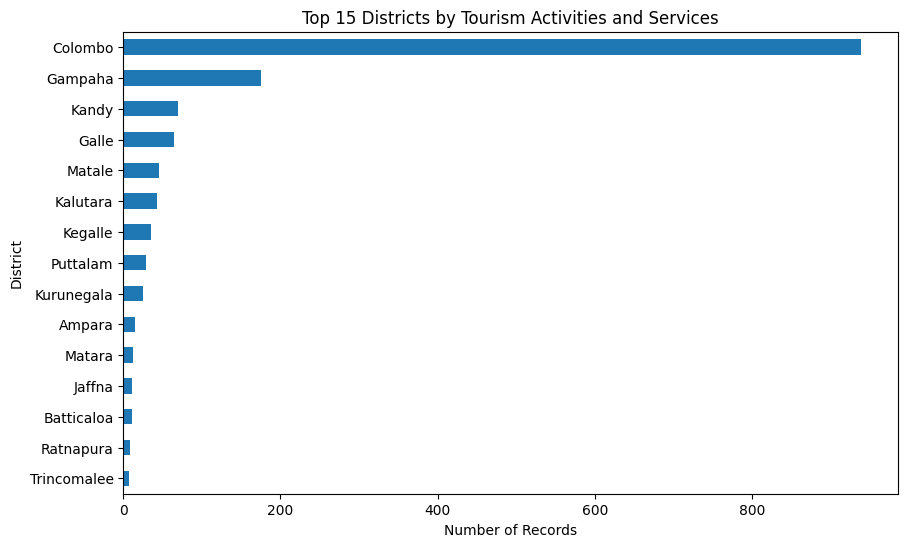

In [35]:
plt.figure(figsize=(10, 6))

activity_district_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Districts by Tourism Activities and Services")
plt.xlabel("Number of Records")
plt.ylabel("District")

plt.show()

In [36]:
water_sports_districts = (
    water_sports["District"]
    .value_counts()
)

print(water_sports_districts)

District
Puttalam       12
Kalutara        4
Matara          3
Kegalle         3
Trincomalee     1
Gampaha         1
Batticaloa      1
Name: count, dtype: int64


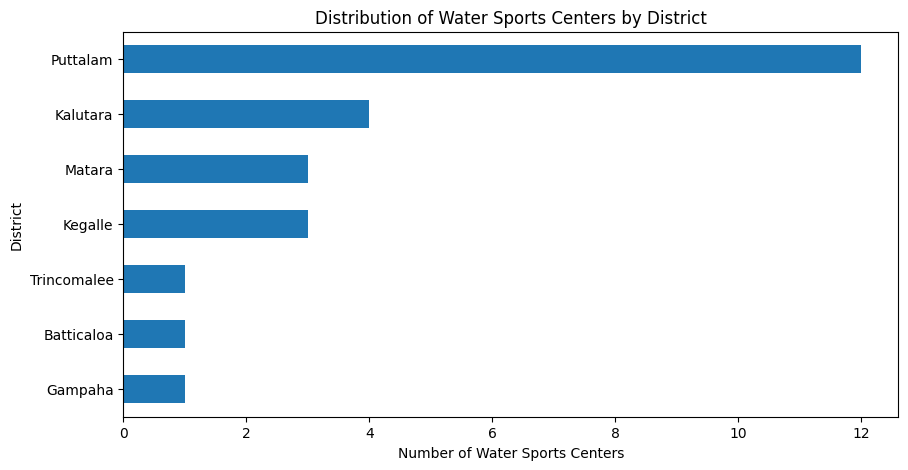

In [37]:
plt.figure(figsize=(10, 5))

water_sports_districts.sort_values().plot(kind="barh")

plt.title("Distribution of Water Sports Centers by District")
plt.xlabel("Number of Water Sports Centers")
plt.ylabel("District")

plt.show()